In [1]:
import cv2

In [2]:
#라이브러리
from pathlib import Path
from PIL import Image
import numpy as np
import cv2
import matplotlib.pyplot as plt

In [113]:
# 이미지 파일 경로
IMAGE_PATH = Path("img/A.jpg")
# 이미지 불러오기
with Image.open(IMAGE_PATH) as img:
    original = img.convert("RGB")
print("Image Size:", original.size)
print("Image Mode:", original.mode)

Image Size: (3289, 4933)
Image Mode: RGB


In [114]:
# 이미지 → NumPy 배열
img_rgb = np.array(original)
print("Shape:", img_rgb.shape)
print("Dtype:", img_rgb.dtype)
print("Pixel:", img_rgb[0, 0])

Shape: (4933, 3289, 3)
Dtype: uint8
Pixel: [9 8 6]


In [115]:
# 예제 04 GrayScale 변환
img_gray = cv2.cvtColor(
img_rgb,
cv2.COLOR_RGB2GRAY
)
print("RGB:", img_rgb.shape)
print("Grayscale:", img_gray.shape) # gray scale 변환 후 shape 확인 채널 표시 없음

RGB: (4933, 3289, 3)
Grayscale: (4933, 3289)


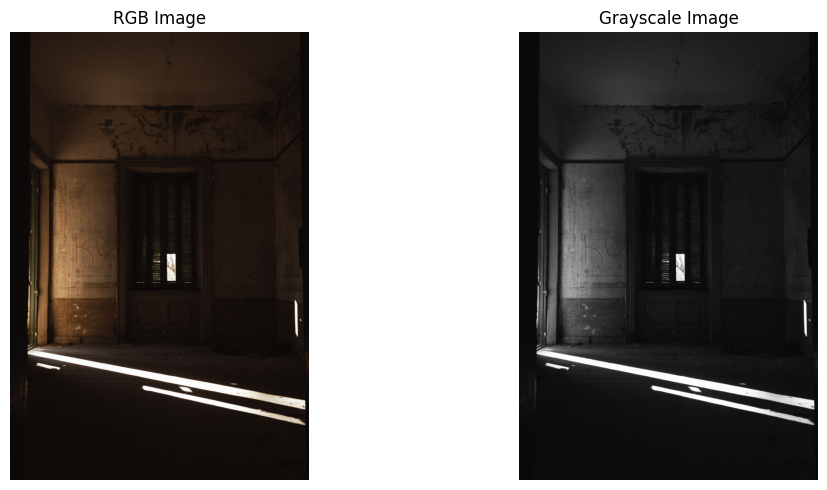

In [6]:
# 이미지 출력하기
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(img_rgb)
axes[0].set_title("RGB Image")

axes[1].imshow(
    img_gray,
    cmap="gray",
    vmin=0,
    vmax=255
)
axes[1].set_title("Grayscale Image")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [46]:
# 예제 06 이미지 리사이즈
# 변경할 이미지 크기
#target_width = 512
#target_height = 512

target_ratio = 0.5
target_width = int(original.size[0] * target_ratio)
target_height = int(original.size[1] * target_ratio)



# 이미지 크기 변경
resized = cv2.resize(
    img_rgb,
    (target_width, target_height),
    interpolation = cv2.INTER_AREA
)

print("Original:", img_rgb.shape)
print("Resized:", resized.shape)

Original: (6587, 4459, 3)
Resized: (3293, 2229, 3)


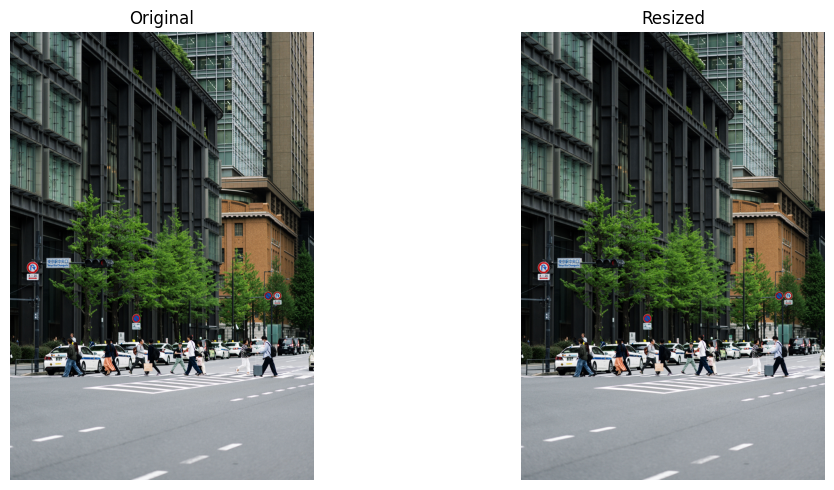

In [47]:
# 예제 07 원본과 Resize 비교

fig, axes = plt.subplots(1, 2, figsize = (12, 5))
axes[0].imshow(img_rgb)
axes[0].set_title("Original")

axes[1].imshow(resized)
axes[1].set_title("Resized")

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()


In [109]:
# 원본 이미지 크기
h, w = img_rgb.shape[:2]

# ROI 크기
cropsize_x = min(1024, w)
cropsize_y = min(1024, h)

# 이미지 중앙에서 시작
left = (w - cropsize_x) // 2
top = (h - cropsize_y) // 2

# 관심 영역 좌표
# box_e = (
#     left,
#     top,
#     left + cropsize_x,
#     top + cropsize_y
# )

left, top = 3200, 4250

# 관심 영역 이동
box_e = (
    left,
    top,
    left + cropsize_x,
    top + cropsize_y
)

print("ROI Box:", box_e)

ROI Box: (3200, 4250, 4224, 5274)


Original: (6587, 4459, 3)
ROI Size: (1024, 1024)


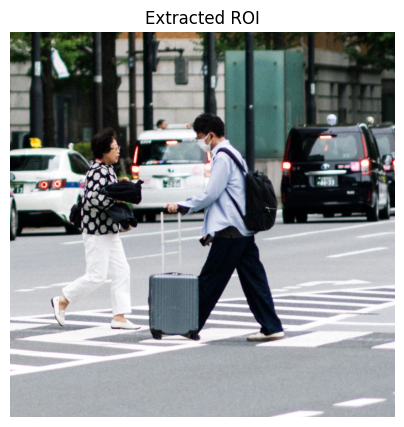

In [110]:
# ROI 추출
# roi_rgb = img_rgb[
#     top:top + cropsize_y,
#     left:left + cropsize_x
# ]
roi_rgb = original.crop(box_e)

print("Original:", img_rgb.shape)
#print("ROI:", roi_rgb.shape)
print("ROI Size:", roi_rgb.size)

plt.figure(figsize=(5, 5))
plt.imshow(roi_rgb)
plt.title("Extracted ROI")
plt.axis("off")
plt.show()

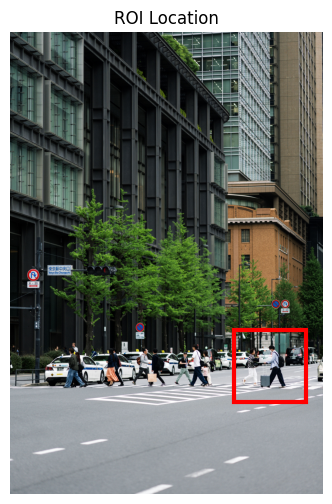

In [111]:
from matplotlib.patches import Rectangle
fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(img_rgb)
rect = Rectangle(
    (left, top),
    cropsize_x,
    cropsize_y,
    fill=False,
    edgecolor="red",
    linewidth=3
)
ax.add_patch(rect)
ax.set_title("ROI Location")
ax.axis("off")
plt.show()

In [116]:
values = np.array([-20, 50, 180, 280])

result = np.clip(
    values,
    0,
    255
    
)

print(result)

[  0  50 180 255]


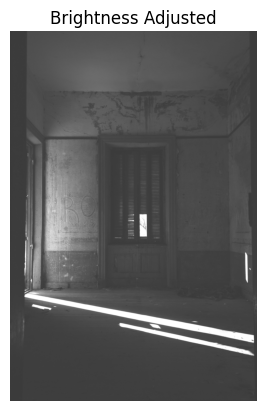

In [ ]:
#밝기 조절 코드 작성

# 계산용 배열 변환
arr = img_gray.astype(np.float32)
#uint8 0~255 범위의 정수형으로 변환

# 밝기 조절값
brightness_offset = 50

# 밝기 증가
bright = np.clip(
    arr + brightness_offset,
    0,
    255
).astype(np.uint8)

plt.imshow(
    bright,
    cmap="gray",
    vmin=0,
    vmax=255
)

plt.title("Brightness Adjusted")
plt.axis("off")
plt.show()

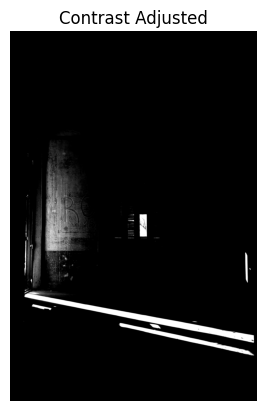

In [132]:
# 예제 13. 대비 조절

# 대비 조절 강도
contrast_factor = 2

# 대비 증가
contrast = np.clip(
(arr - 128) * contrast_factor + 128,
0,
255
).astype(np.uint8)
plt.imshow(
contrast,
cmap="gray",
vmin=0,
vmax=255
)
plt.title("Contrast Adjusted")
plt.axis("off")
plt.show()

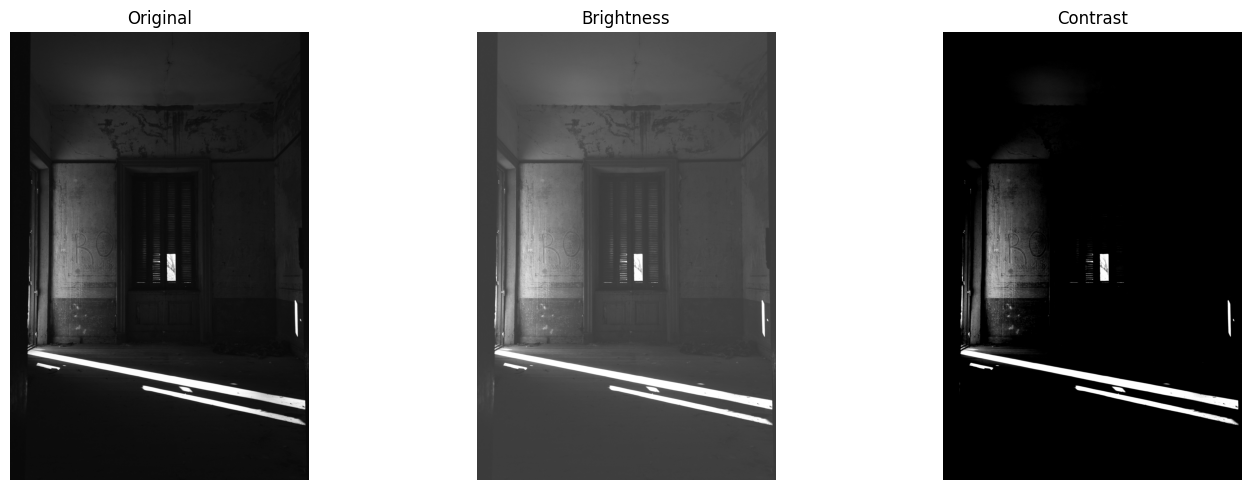

In [120]:
#예제 14. 처리 결과 비교
images = [img_gray, bright, contrast]

title = [
    "Original",
    "Brightness",
    "Contrast"
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, image, title in zip(axes, images, title):
    ax.imshow(
        image,
        cmap="gray",
        vmin=0,
        vmax=255
    )
    ax.set_title(title)
    ax.axis("off")
    
plt.tight_layout()
plt.show()

In [121]:
clahe = cv2.createCLAHE(
clipLimit=2.0,
tileGridSize=(8, 8)
)

In [122]:
clahe_img = clahe.apply(img_gray)

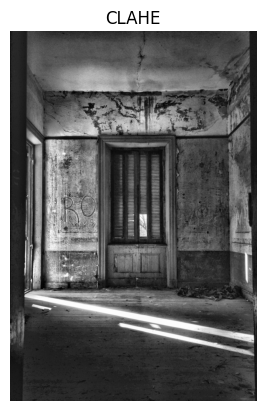

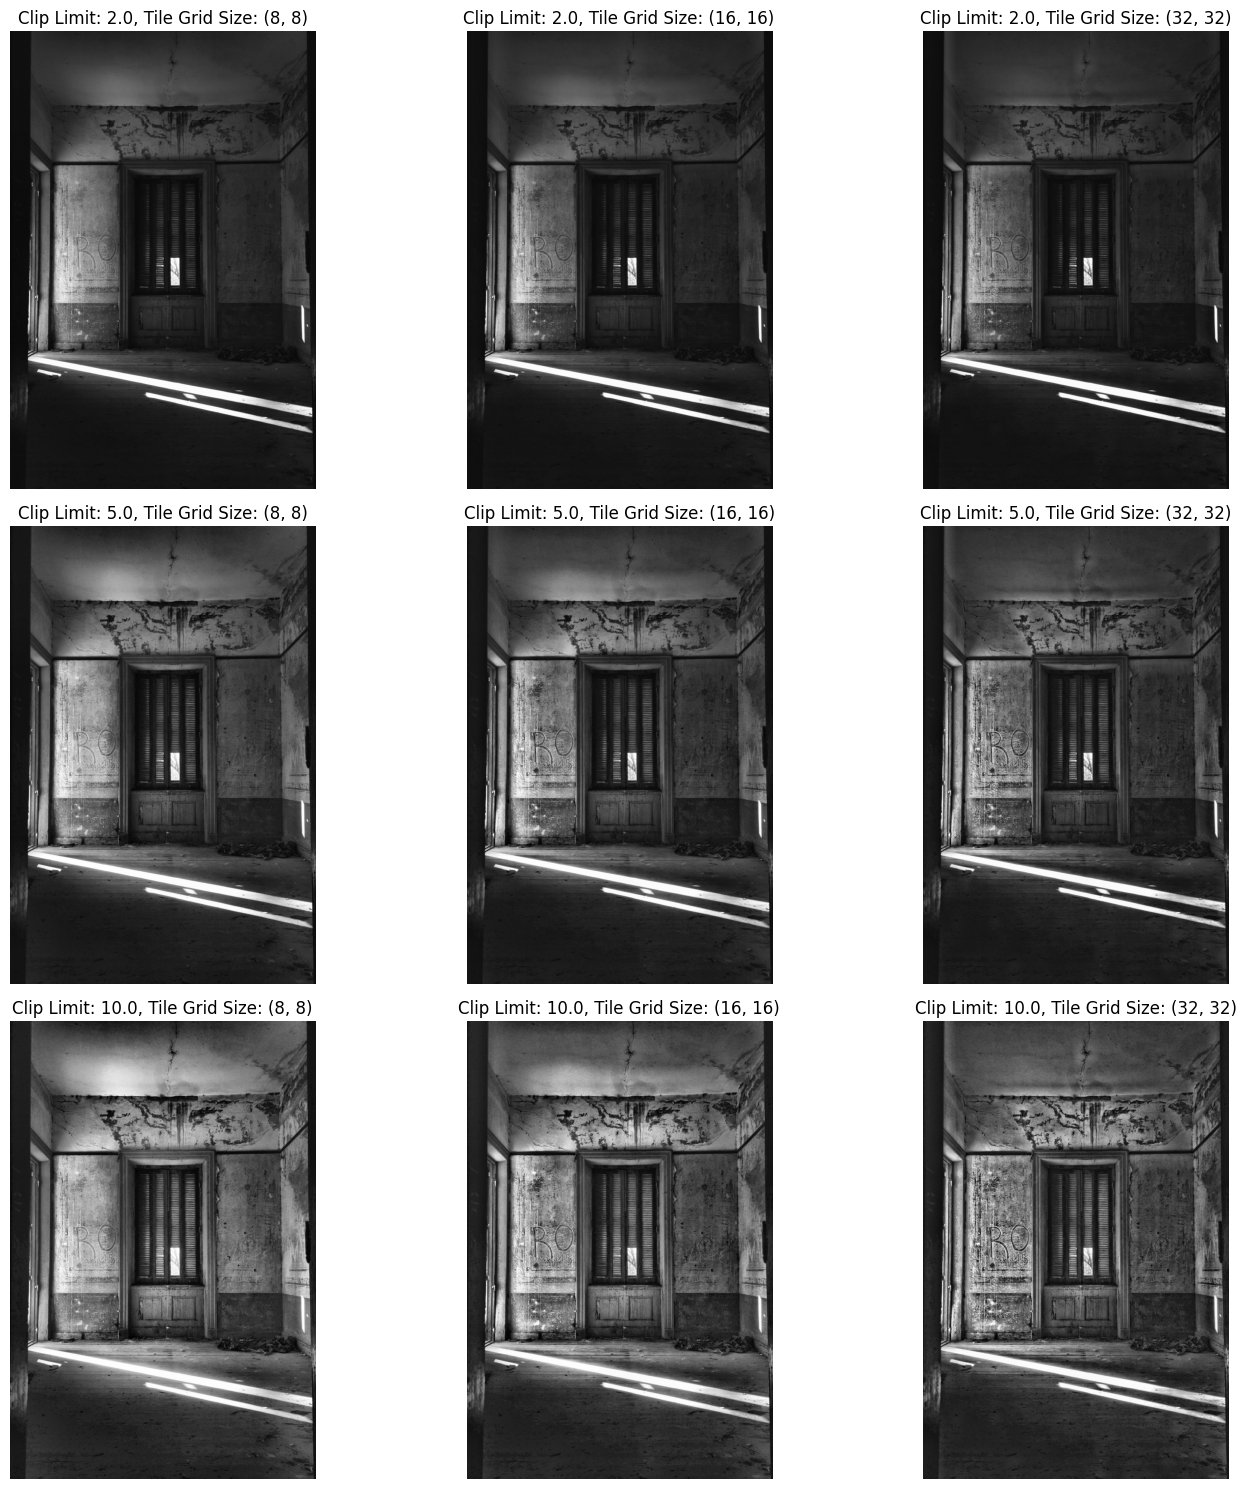

In [136]:
#예제 15. CLAHE 적용
clip_limit = 10.0
tile_grid_size = (16, 16)

# CLAHE 객체 생성
clahe = cv2.createCLAHE(
    clipLimit=clip_limit,
    tileGridSize=tile_grid_size
)

# 이미지 처리
clahe_img = clahe.apply(img_gray)

plt.imshow(
    clahe_img,
    cmap="gray",
    vmin=0,
    vmax=255
)

plt.title("CLAHE")
plt.axis("off")
plt.show()


# Clip limit과 tileGridSize 변경에 따른 결과 비교
clip_limits = [2.0, 5.0, 10.0]
tile_grid_sizes = [(8, 8), (16, 16), (32, 32)]

# 이미지 3개를 나란히 출력
fig, axes = plt.subplots(3, 3, figsize=(15, 15))

for i, clip_limit in enumerate(clip_limits):
    for j, tile_grid_size in enumerate(tile_grid_sizes):
        # CLAHE 객체 생성
        clahe = cv2.createCLAHE(
            clipLimit=clip_limit,
            tileGridSize=tile_grid_size
        )
        
        # 이미지 처리
        clahe_img = clahe.apply(img_gray)
        
        # 결과 출력
        ax = axes[i, j]
        ax.imshow(
            clahe_img,
            cmap="gray",
            vmin=0,
            vmax=255
        )
        ax.set_title(f"Clip Limit: {clip_limit}, Tile Grid Size: {tile_grid_size}")
        ax.axis("off")
        
        
        
plt.tight_layout()
plt.show()


In [124]:
images = [
img_gray,
bright,
contrast,
clahe_img
]
titles = [
"Original",
"Brightness",
"Contrast",
"CLAHE"
]

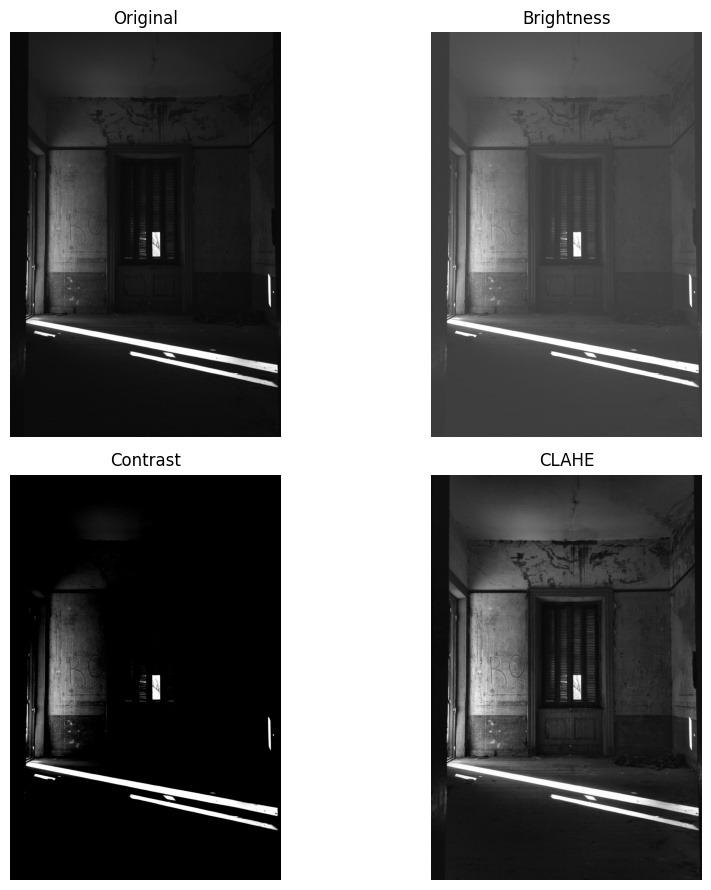

In [125]:
fig, axes = plt.subplots(2, 2, figsize=(10, 9))

for ax, image, title in zip(axes.flat, images, titles):
    ax.imshow(
            image,
            cmap="gray",    
            vmin=0,
            vmax=255
    )
    ax.set_title(title)
    ax.axis("off")
    
plt.tight_layout()
plt.show()      

In [ ]:
# 2. 밝기와 대비 조절
# - 밝기 조절이 이뤄지는 부분과 계산 방식
# - 대비 조절이 이뤄지는 부분과 계산 방식

# 3. CLAHE를 이용한 국소 대비 조절
# - CLAHE 설정값 변경에 따른 결과 차이


In [ ]:
# 예제 17. CLAHE 결과 저장
# 저장 폴더
OUTPUT_DIR = Path("output_part2")
OUTPUT_DIR.mkdir(
parents=True,
exist_ok=True
)
# 저장할 이미지 파일 경로
save_path = OUTPUT_DIR / "clahe_result.png"
# 배열 → 이미지 객체 → 파일 저장
Image.fromarray(clahe_img).save(save_path)
print("Saved:", save_path)

Saved: output_part2\clahe_result.png


Loaded Image: (4933, 3289)


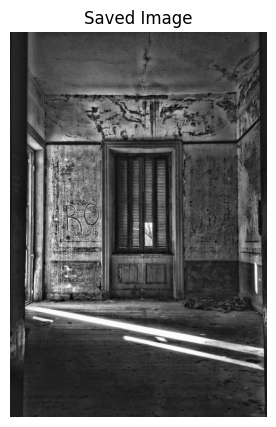

In [138]:
# 예제 18. 저장 이미지 확인
# 저장된 파일 불러오기
with Image.open(save_path) as img:
    loaded = np.array(img)
    
print("Loaded Image:", loaded.shape)

plt.figure(figsize=(8, 5))
plt.imshow(
    loaded,
    cmap="gray",
    vmin=0,
    vmax=255
)
plt.title("Saved Image")
plt.axis("off")
plt.show()
